# Нейронные сети








### Физиологическая модель нейрона

Нейрон (нервная клетка) состоит из:
- тела клетки (cell body),
- внешних ветвей:
    - аксона (axon)
    - дендритов (dendrites).

Тело клетки включает:
- ядро (nucleus), которое содержит информацию о наследственных свойствах,
- плазму, обладающую молекулярными средствами для производства необходимых нейрону материалов.

Нейрон получает сигналы (импульсы) от других нейронов через дендриты (приемники) и передает сигналы, сгенерированные телом клетки, вдоль аксона (передатчик), который в конце разветвляется на волокна (strands). На окончаниях этих волокон находятся синапсы (synapses).

Кора головного мозга человека :
 - поверхностью толщиной от 2 до 3 мм с площадью около 2200 см2.
 - 10^11 нейронов.
 - нейрон связан с 10^3 – 10^4 другими нейронами.
 - мозг человека содержит приблизительно от 10^14 до 10^15 взаимосвязей.


In [ ]:
from IPython.display import Image

<img src='https://drive.google.com/uc?export=view&id=1CHbSfdsKulHIFhb93h_cevvb6ApaSNTx'>


## Формальные модели нейрона

In [ ]:
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt


### Нейрон МакКалока-Питтса

<img src='https://drive.google.com/uc?export=view&id=1y5ee6Wz6kTMEDpmbc76omk6jXQt2mmmn'>


Построим пример обработки входного х как в нейроне

In [ ]:
x = np.array([1,0])
w = np.array([1,-1])

y = np.sign(np.dot(w, x.T )-9.3)
print(y)

-1.0


Посторим нейрон порогового типа

In [ ]:
def McCuloh_Pitts_neuron(x = None, w = None, bias = 0):
    # w - веса
    # x - входы
    s = x @ w + bias
    y = np.sign(s)
    #ind_ = np.where(s>0)[0]
    #y=np.zeros(x.shape[0])
    #y[ind_]=1
    return y

Запустим нейрон на примре х с весами w

In [ ]:
x = np.array([1,0])
w = np.array([1,-1])

y_out = McCuloh_Pitts_neuron(x = x, w = w, bias = -0.3)
print('ответ нейрона',y_out)

ответ нейрона 1.0


Подадим много примеров через х и получим много ответов

In [ ]:
x = np.random.random((10,2))
w = np.array([1,-1])
y_out1 = McCuloh_Pitts_neuron(x = x, w = w, bias = 0.3)
print('ответ нейрона',y_out1)

ответ нейрона [ 1.  1. -1.  1.  1.  1.  1.  1.  1.  1.]


### **Задание 1**
1.1 собрать реализацию модели нейронов с функцией активации:
- линейной
- сигмоидной
- тангенциальной
- сложной сигмоидной

1.2 построить визуализацию выходов на одинаковом множестве входов

1.3 перечислить достоинства и недостатки активаций

### Линейный нейрон

Линейный нейрон связывает входы в форме y = XW + b

Сделать реализацию функции linear_neuron(x: float = None, w: float = None, bias: float = 0) , где х - входы, w - веса, b - сдвиг

In [ ]:
def linear_neuron(x, w, bias=0):
    if x.ndim == 1:
        x = x.reshape(1, -1)
    return x @ w + bias

Запустим нейрон на множестве примеров в х

In [ ]:
x = np.random.random((10,2))
w = np.array([1,-1])
y_out1 = linear_neuron(x = x, w = w, bias = 0.3)
print('ответ нейрона',y_out1)

ответ нейрона [ 0.40248603 -0.11028623 -0.22083034  0.76725595  1.02504978 -0.57483131
 -0.10126016  0.26494011  1.10758159  0.45310293]


### Сигмоидный нейрон

Строим сигмоидный нейрон логистический как s = X W + b, y = 1/(1+ exp(-s))


sigmoid_neuron(x: float = None, w: float = None, bias: float = 0)

In [ ]:
def sigmoid_neuron(x: float = None, w: float = None, bias: float = 0):
    y_pred = x @ w + bias
    exp_y_pred = np.exp(-y_pred)
    return 1./(1 + exp_y_pred)

Строим сигмоидный нейрон тангенциальный как s = X W + b, y = 2/(1+ exp(-s))-1

sigmoidt_neuron(x: float = None, w: float = None, bias: float = 0)

In [ ]:
def sigmoidt_neuron(x: float = None, w: float = None, bias: float = 0):
    y_pred = x @ w + bias
    th = 2./(1+np.exp(-2*y_pred)) - 1
    return th

Запустим нейрон

In [ ]:
y_out2 = sigmoidt_neuron(x = x, w = w, bias = 0.3)
print('ответ нейрона',y_out2)

ответ нейрона [ 0.3820741  -0.10984126 -0.21730933  0.645331    0.77191536 -0.51889857
 -0.10091548  0.25891035  0.80320586  0.42444628]


Запустим все нейроны на множестве примеров (линейно равномерно распределены в интервале от -10 до 10)

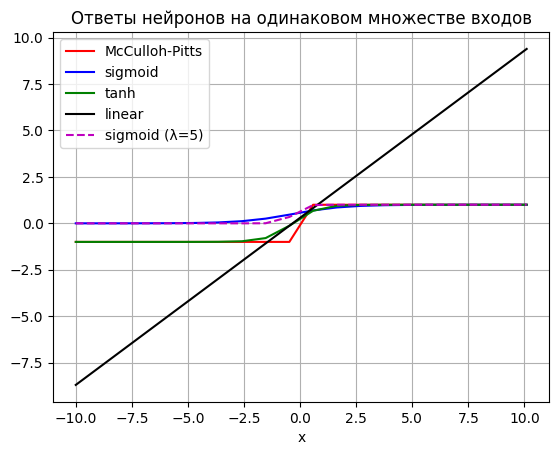

In [ ]:
x = np.linspace(-10,10.1,20).reshape((20,1))
w = np.array([0.9]).reshape((1,1))
bias = 0.3

def sigmoidt_complex_neuron(x:float=None, w:float=None, bias:float=0, lymbd:float=1):
    y_pred = x @ w + bias
    return 1./(1 + np.exp(-lymbd * y_pred))

y_out1 = McCuloh_Pitts_neuron(x = x, w = w, bias = bias)
y_out2 = sigmoid_neuron(x = x, w = w, bias = bias)
y_out3 = sigmoidt_neuron(x = x, w = w, bias = bias)
y_out4 = linear_neuron(x = x, w = w, bias = bias)
# добавляем сложную сигмоиду (λ=5 — чтобы визуально отличалась от обычной)
y_out5 = sigmoidt_complex_neuron(x = x, w = w, bias = bias, lymbd=5)

plt.plot(x[:,0], y_out1[:,0], 'r', label='McCulloh-Pitts')
plt.plot(x[:,0], y_out2[:,0], 'b', label='sigmoid')
plt.plot(x[:,0], y_out3[:,0], 'g', label='tanh')
plt.plot(x[:,0], y_out4[:,0], 'k', label='linear')                 # ← добавлено
plt.plot(x[:,0], y_out5[:,0], 'm--', label='sigmoid (λ=5)')        # ← добавлено

plt.legend()
plt.title('Ответы нейронов на одинаковом множестве входов')
plt.xlabel('x')
plt.grid()
plt.show()

Отвеы нейронов для разных нейронов

Пороговый:

In [ ]:
y_out1

array([[-1.],
       [-1.],
       [-1.],
       [-1.],
       [-1.],
       [-1.],
       [-1.],
       [-1.],
       [-1.],
       [-1.],
       [ 1.],
       [ 1.],
       [ 1.],
       [ 1.],
       [ 1.],
       [ 1.],
       [ 1.],
       [ 1.],
       [ 1.],
       [ 1.]])

Сигмоидный нейрон:

In [ ]:
y_out2

array([[1.66558065e-04],
       [4.31464081e-04],
       [1.11722503e-03],
       [2.88977058e-03],
       [7.45358282e-03],
       [1.90870489e-02],
       [4.79997991e-02],
       [1.15549948e-01],
       [2.52908880e-01],
       [4.67283653e-01],
       [6.94459739e-01],
       [8.54849947e-01],
       [9.38501009e-01],
       [9.75334342e-01],
       [9.90334440e-01],
       [9.96247521e-01],
       [9.98548470e-01],
       [9.99439314e-01],
       [9.99783541e-01],
       [9.99916452e-01]])

Сигмоидный тангенциальный нейрон:

In [ ]:
y_out3

array([[-0.99999994],
       [-0.99999963],
       [-0.9999975 ],
       [-0.9999832 ],
       [-0.99988722],
       [-0.99924302],
       [-0.99492855],
       [-0.96643608],
       [-0.79436723],
       [-0.13030748],
       [ 0.67564239],
       [ 0.9439545 ],
       [ 0.99144863],
       [ 0.99872171],
       [ 0.99980951],
       [ 0.99997163],
       [ 0.99999577],
       [ 0.99999937],
       [ 0.99999991],
       [ 0.99999999]])

Усложним сигмоидный нейрон сигмоид с коэффициентом наклона

sigmoidt_complex_neuron(x:float=None, w:float=None, bias:float=0, lymbd:float=1)

Посмотрим на работу нейнона

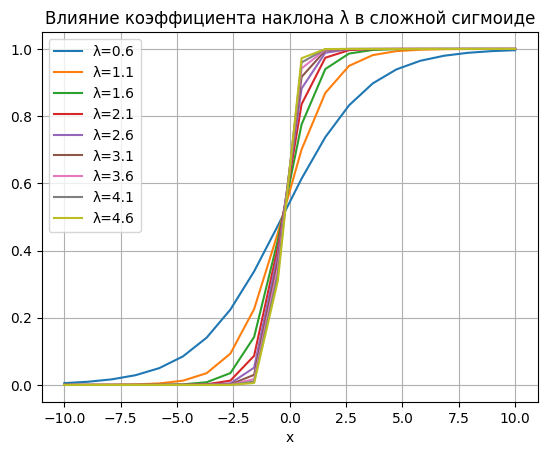

In [ ]:
x = np.linspace(-10,10,20).reshape((20,1))
w = np.array([0.9]).reshape((1,1))
bias =0.3

for i in range(1, 10):
    lam = 0.1 + i*0.5
    y_out3 = sigmoidt_complex_neuron(x = x, w = w, bias = 0.3, lymbd=lam)
    plt.plot(x[:, 0], y_out3[:, 0], label=f'λ={lam:.1f}')

plt.title('Влияние коэффициента наклона λ в сложной сигмоиде')
plt.xlabel('x')
plt.legend()
plt.grid()
plt.show()

### 1.3 Достоинства и недостатки функций активации

**Линейная (y = s)**
- плюс: Простая, дифференцируемая
- минус: Не способна решать нелинейные задачи (XOR, круг и т.п.)

**Сигмоида (y = 1 / (1 + e⁻ˢ))**
- плюс: Гладкая, дифференцируемая, выход в (0; 1) — удобно для вероятностей
- минус: Выход не центрирован около нуля → медленная сходимость

**Гиперболический тангенс (y = 2/(1+e⁻²ˢ) − 1 = tanh(s))**
- плюс: Гладкая, дифференцируемая, выход в (−1; 1)
- минус: Не подходит для выхода вероятностной классификации

**Сложная сигмоида (y = 1 / (1 + e^(−λ·s)))**
- плюс: Управляемая крутизна перехода (λ): при λ→∞ стремится к пороговой функции
- минус: Требует подбора λ как гиперпараметра

### **Задание 2**

2.1. Визуализировать выход 2хмерного нейрона в разных вариантах активаций

**Двухмерный нейрон**

строим поле координат 10х10

In [ ]:
x1 = np.array([np.linspace(-10,11,10).reshape((10,1))]*10).reshape((10,10))
x2 = x1.T
x2=x2.reshape((100,1))
x1=x1.reshape((100,1))
print(x1[:3])
print(x2[:3])

x = np.hstack([x1,x2])

[[-10.        ]
 [ -7.66666667]
 [ -5.33333333]]
[[-10.]
 [-10.]
 [-10.]]


Разменость данных

In [ ]:
x.shape
w1 = np.array([0.9, -0.9])
w1.shape

(2,)

Строим поверхность двухмерного нейрона  (чем желтее, тем ближе к 1, чем синее, тем ближе к -1)

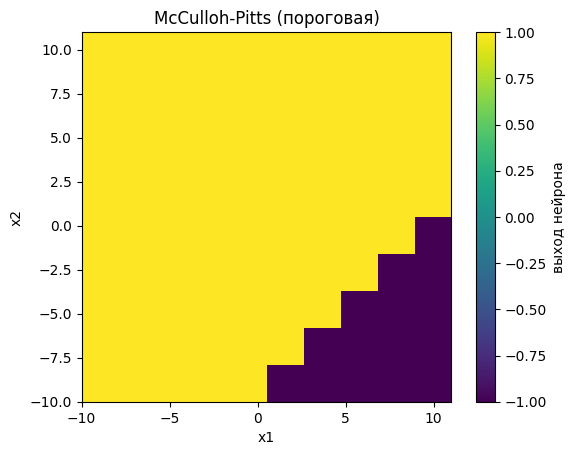

In [ ]:
w = np.array([-0.9, 0.9])

y_out_21 = McCuloh_Pitts_neuron(x=x, w=w, bias=10).reshape((10, 10))

plt.imshow(y_out_21, vmin=-1, vmax=1, origin='lower',
           extent=[-10, 11, -10, 11], cmap='viridis')
plt.colorbar(label='выход нейрона')
plt.title('McCulloh-Pitts (пороговая)')
plt.xlabel('x1'); plt.ylabel('x2')
plt.show()

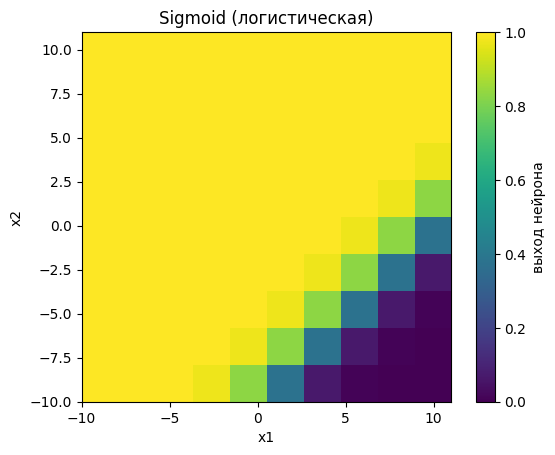

In [ ]:
w = np.array([-0.9, 0.9])

y_out_22 = sigmoid_neuron(x=x, w=w, bias=10).reshape((10, 10))

plt.imshow(y_out_22, vmin=0, vmax=1, origin='lower',
           extent=[-10, 11, -10, 11], cmap='viridis')
plt.colorbar(label='выход нейрона')
plt.title('Sigmoid (логистическая)')
plt.xlabel('x1'); plt.ylabel('x2')
plt.show()

Сигмоидный нейрон на том же пространстве

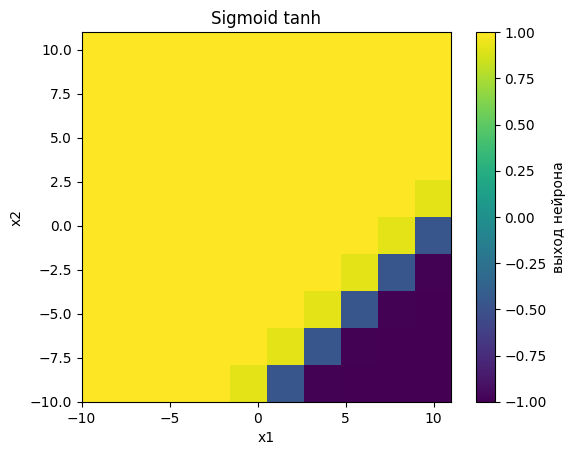

In [ ]:
w = np.array([-0.9, 0.9])

y_out_23 = sigmoidt_neuron(x=x, w=w, bias=10).reshape((10, 10))

plt.imshow(y_out_23, vmin=-1, vmax=1, origin='lower',
           extent=[-10, 11, -10, 11], cmap='viridis')
plt.colorbar(label='выход нейрона')
plt.title('Sigmoid tanh')
plt.xlabel('x1'); plt.ylabel('x2')
plt.show()

И еще один нейрон

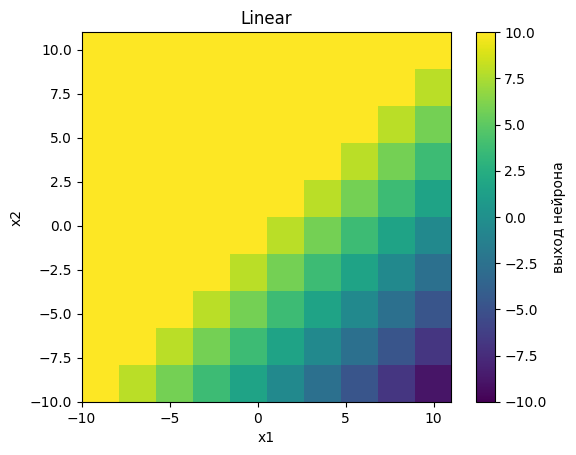

In [ ]:
w = np.array([-0.9, 0.9])

y_out_24 = linear_neuron(x=x, w=w, bias=10).reshape((10, 10))

plt.imshow(y_out_24, vmin=-10, vmax=10, origin='lower',
           extent=[-10, 11, -10, 11], cmap='viridis')
plt.colorbar(label='выход нейрона')
plt.title('Linear')
plt.xlabel('x1'); plt.ylabel('x2')
plt.show()

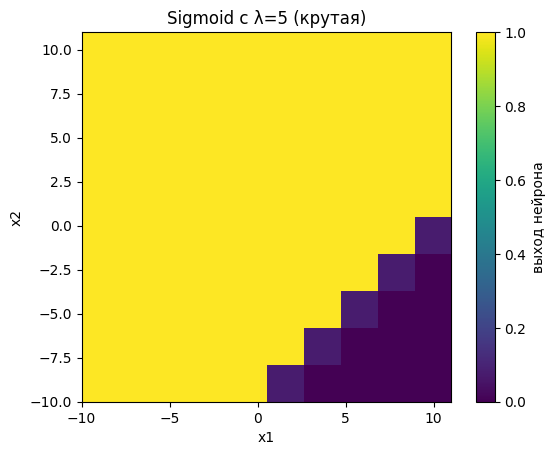

In [ ]:
w = np.array([-0.9, 0.9])

y_out_25 = sigmoidt_complex_neuron(x=x, w=w, bias=10, lymbd=5).reshape((10, 10))

plt.imshow(y_out_25, vmin=0, vmax=1, origin='lower',
           extent=[-10, 11, -10, 11], cmap='viridis')
plt.colorbar(label='выход нейрона')
plt.title('Sigmoid с λ=5 (крутая)')
plt.xlabel('x1'); plt.ylabel('x2')
plt.show()

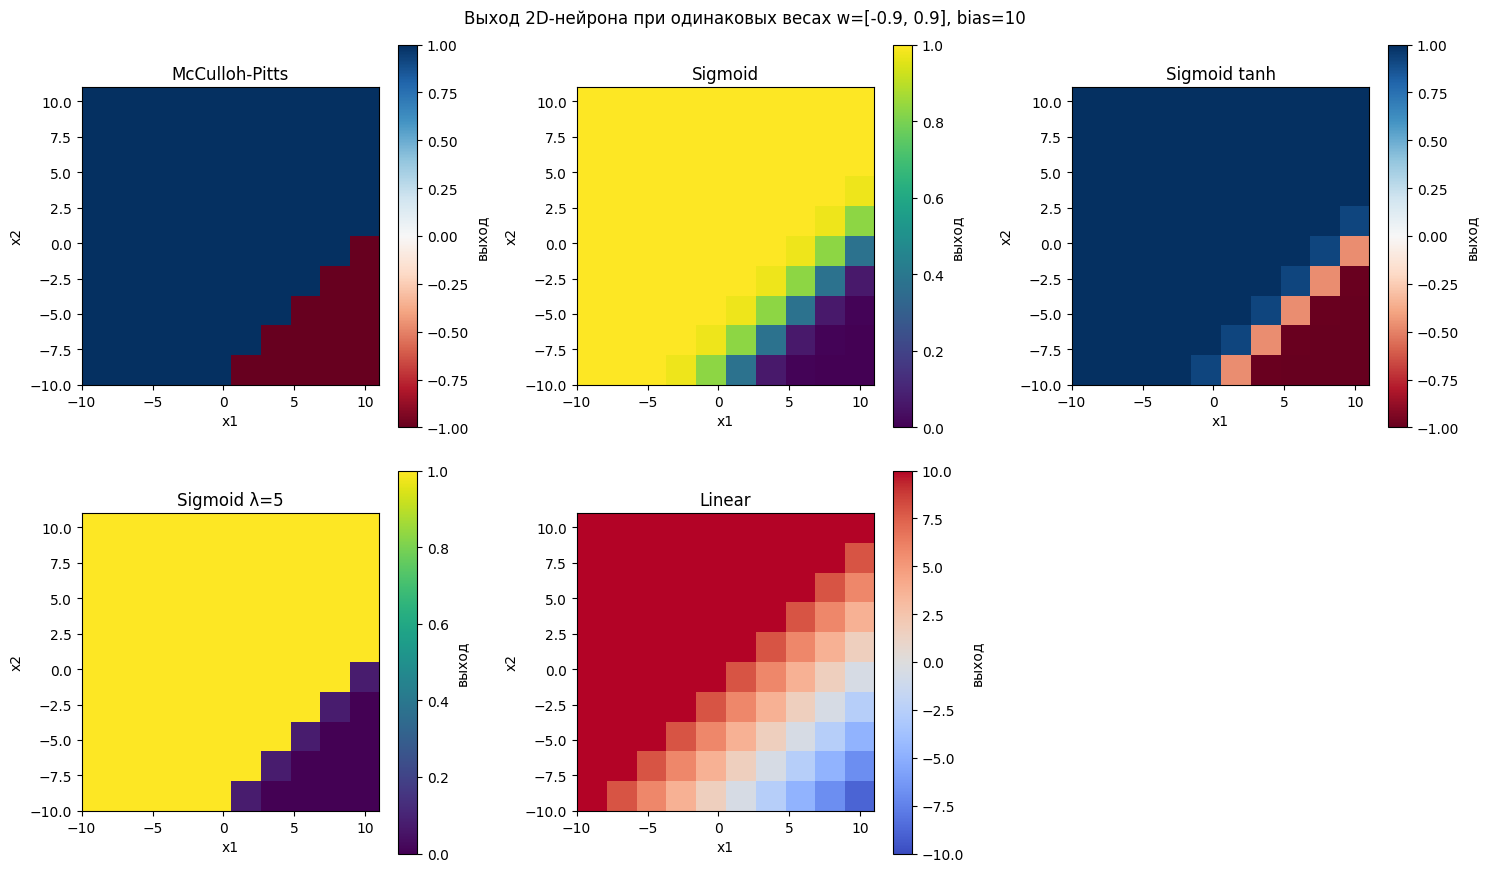

In [ ]:
fig, axes = plt.subplots(2, 3, figsize=(15, 9))

items = [
    (y_out_21, 'McCulloh-Pitts',  -1,  1, 'RdBu'),
    (y_out_22, 'Sigmoid',          0,  1, 'viridis'),
    (y_out_23, 'Sigmoid tanh',    -1,  1, 'RdBu'),
    (y_out_25, 'Sigmoid λ=5',      0,  1, 'viridis'),
    (y_out_24, 'Linear',         -10, 10, 'coolwarm'),
]

for ax, (y, title, vmin, vmax, cmap) in zip(axes.flat, items):
    im = ax.imshow(y, vmin=vmin, vmax=vmax, origin='lower',
                   extent=[-10, 11, -10, 11], cmap=cmap)
    ax.set_title(title)
    ax.set_xlabel('x1'); ax.set_ylabel('x2')
    plt.colorbar(im, ax=ax, label='выход')

axes.flat[-1].axis('off')
plt.suptitle('Выход 2D-нейрона при одинаковых весах w=[-0.9, 0.9], bias=10')
plt.tight_layout()
plt.show()

И еще один нейрон

Все нейроны отличаются весами, что приводит к разным выходам.

### **Задание 3**

3.1. Сделать реализацию обучения по Дельта-правилу(правило Вудро-Хофа) для линейного нейрона

3.2. Сделать реализацию обучения по Дельта-правилу для сигмоидного нейрона

3.3. визуализировать результат обучения для набора данных :

**# входное пространство**

x1 = np.array([1,1,-1,-1])
x2 = np.array([1,-1,-1,1])

x = np.vstack([x1,x2]).T

**# целевые значения для входов**

D=np.array([1,1,-1,-1])

**Обучение линейного нейрона**

1. Задать начальное состояние
2. Взять пример j из набора примеров
3. Вычислить выход нейрона для этого примера
4. Вычислить коррекцию синаптических весов для всех входов xi

dwi = - n (y(Хj) - dj) xi

5. Вычислить новый уровень wi
wi = wi +  dwi

6. Перейти к новому примеру в п.2
7. Если просмотрели все примеры, то проверить условие конца (ошибка модели или число повторов):
    - условие выполнено - конец
    - условие не выполнено - начинаем просматривать примеры и изменять веса сначала (j=0) и к п.2
    


Эпоха - просмотр всех примеров из набора

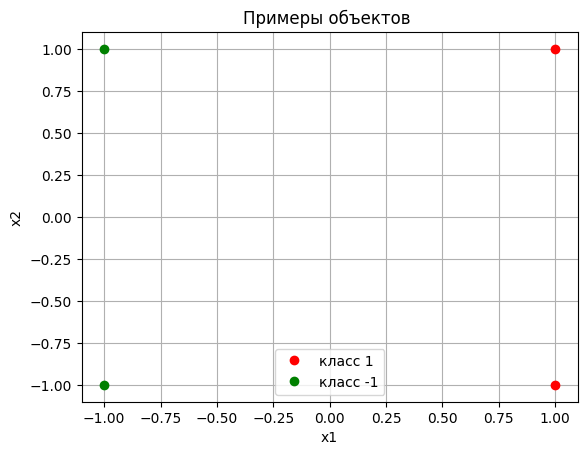

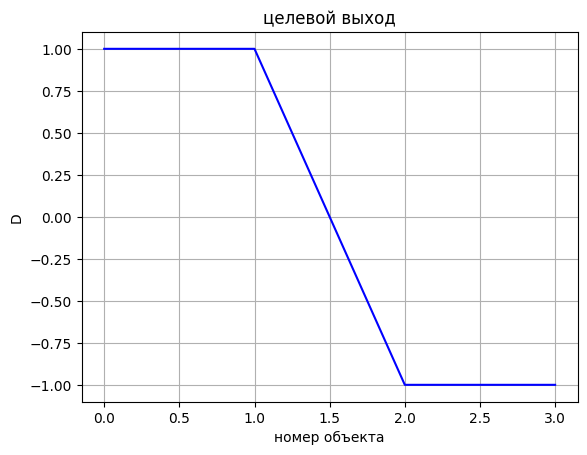

In [ ]:
x1 = np.array([1,1,-1,-1])
x2 = np.array([1,-1,-1,1])

x = np.vstack([x1,x2]).T

D=np.array([1,1,-1,-1])
plt.plot(x1[:2],x2[:2], 'or', label = 'класс 1')
plt.plot(x1[2:4],x2[2:4], 'og', label = 'класс -1')
plt.legend()
plt.xlabel('x1')
plt.ylabel('x2')
plt.title('Примеры объектов ')
plt.grid()
plt.show()

plt.plot(D, 'b')
plt.title('Примеры значений класса ')
plt.title('целевой выход')
plt.xlabel('номер объекта')
plt.ylabel('D')
plt.grid()
plt.show()

Посмотрим на входы

In [ ]:
x.shape

(4, 2)

Научим нейрон понимать эти примеры

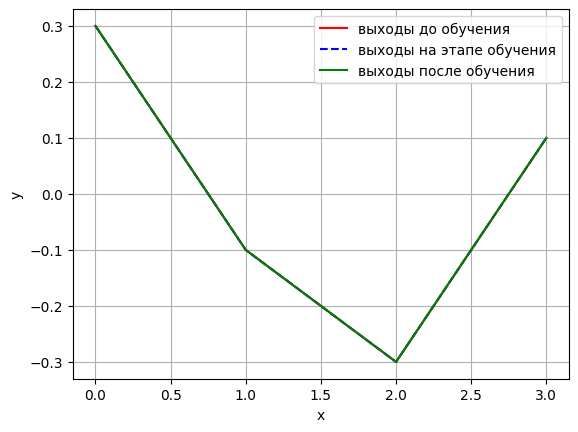

In [ ]:
w=np.array([0.1, 0.2])

yt = linear_neuron(x = x, w = w, bias = 0)
plt.plot(yt, 'r', label = 'выходы до обучения')


## реализовать обучение нейрона

plt.plot(yt,'--b', label = 'выходы на этапе обучения')
plt.plot(yt,'g', label = 'выходы после обучения')
plt.legend()
plt.xlabel('x')
plt.ylabel('y')
plt.grid()
plt.show()

**Обучение линейного нейрона**

1. Задать начальное состояние
2. Взять пример j из набора примеров
3. Вычислить выход нейрона для этого примера
4. Вычислить коррекцию синаптических весов для всех входов xi

dwi = - n (y(Хj) - dj) xi

5. Вычислить новый уровень wi
wi = wi +  dwi

6. Перейти к новому примеру в п.2
7. Если просмотрели все примеры, то проверить условие конца (ошибка модели или число повторов):
    - условие выполнено - конец
    - условие не выполнено - начинаем просматривать примеры и изменять веса сначала (j=0) и к п.2
    


Эпоха - просмотр всех примеров из набора

In [ ]:
def delta_rule_linear(x, D, w_init, b_init=0.0, lr=0.01, epochs=100):
    w = np.array(w_init, dtype=float)
    b = float(b_init)
    history = [x @ w + b]
    for epoch in range(epochs):
        for j in range(len(x)):
            y_pred = x[j] @ w + b
            err = D[j] - y_pred
            w = w + lr * err * x[j]
            b = b + lr * err
        history.append(x @ w + b)
    return w, b, history

In [ ]:

w_init = np.array([0.1, 0.2])
b_init = 0.0
w_delta, b_delta, history_delta = delta_rule_linear(x, D, w_init, b_init, lr=0.01, epochs=50)

print("Веса после дельта-правила:", w_delta)
print("Bias после дельта-правила:", b_delta)
print("Выходы:", x @ w_delta + b_delta)

Веса после дельта-правила: [0.88215573 0.02747117]
Bias после дельта-правила: 2.7486424226180403e-06
Выходы: [ 0.90962965  0.85468731 -0.90962415 -0.85468182]


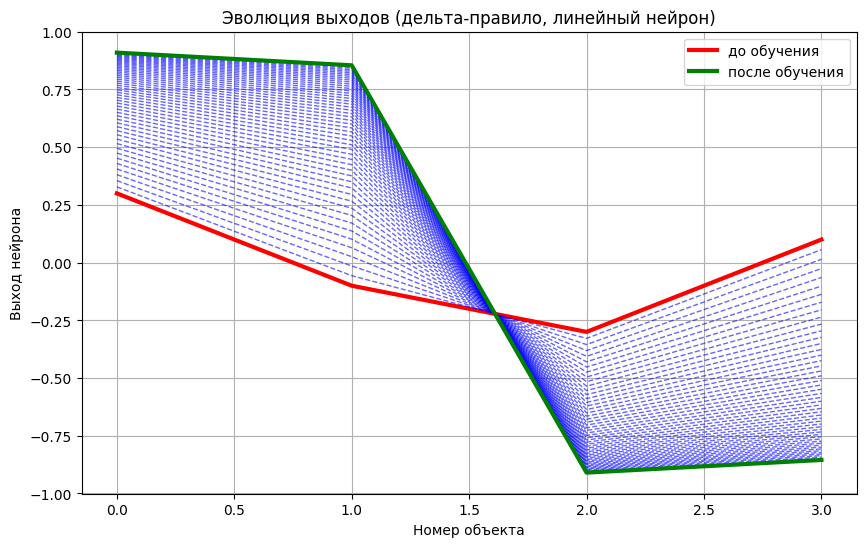

In [ ]:
plt.figure(figsize=(10, 6))

history = np.array(history_delta)

plt.plot(history[0], 'r-', linewidth=3, label='до обучения')

for i in range(1, len(history)-1):
    plt.plot(history[i], 'b--', alpha=0.6, linewidth=1)

plt.plot(history[-1], 'g-', linewidth=3, label='после обучения')

plt.title('Эволюция выходов (дельта-правило, линейный нейрон)')
plt.xlabel('Номер объекта')
plt.ylabel('Выход нейрона')
plt.legend()
plt.grid()
plt.show()

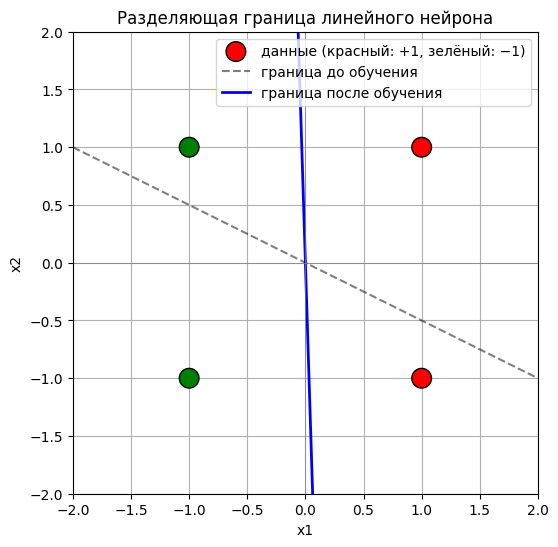

In [ ]:
plt.figure(figsize=(6, 6))
plt.scatter(x1, x2, c=['red', 'red', 'green', 'green'],
            s=200, edgecolors='k', zorder=3,
            label='данные (красный: +1, зелёный: −1)')

x1_line = np.linspace(-2, 2, 100)

x2_before = -(w_init[0] * x1_line + b_init) / w_init[1]
plt.plot(x1_line, x2_before, 'k--', alpha=0.5, label='граница до обучения')

x2_after = -(w_delta[0] * x1_line + b_delta) / w_delta[1]
plt.plot(x1_line, x2_after, 'b-', linewidth=2, label='граница после обучения')

plt.xlim(-2, 2); plt.ylim(-2, 2)
plt.axhline(0, color='gray', linewidth=0.5)
plt.axvline(0, color='gray', linewidth=0.5)
plt.xlabel('x1'); plt.ylabel('x2')
plt.title('Разделяющая граница линейного нейрона')
plt.legend()
plt.grid(True)
plt.show()

In [ ]:
D = np.array([1, 1, -1, -1])
new_D = (D + 1) // 2
def delta_rule_sigmoid(x, D, w_init, b_init=0.0, lr=0.5, epochs=500):
    w = np.array(w_init, dtype=float)
    b = float(b_init)
    history = [1.0 / (1.0 + np.exp(-(x @ w + b)))]
    for epoch in range(epochs):
        for j in range(len(x)):
            s = x[j] @ w + b
            y = 1.0 / (1.0 + np.exp(-s))
            grad = (D[j] - y) * y * (1.0 - y)
            w = w + lr * grad * x[j]
            b = b + lr * grad
        history.append(1.0 / (1.0 + np.exp(-(x @ w + b))))
    return w, b, history

w_s, b_s, history_s = delta_rule_sigmoid(x, new_D, w_init=np.array([-0.5, 0.1]),
                                          b_init=0.01, lr=0.5, epochs=500)
print("Веса сигмоида:", w_s)
y_after = 1 / (1 + np.exp(-(x @ w_s + b_s)))
print("Выходы:", y_after)
print("Классы:", (y_after > 0.5).astype(int))

Веса сигмоида: [3.72913846e+00 1.11997669e-03]
Выходы: [0.97657609 0.9765248  0.0234256  0.0234769 ]
Классы: [1 1 0 0]


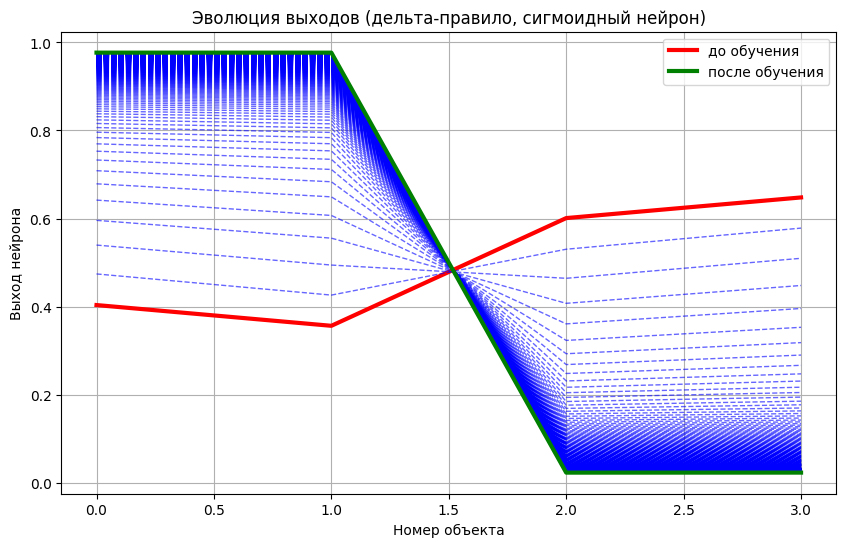

In [ ]:
plt.figure(figsize=(10, 6))
history_s = np.array(history_s)

plt.plot(history_s[0], 'r-', linewidth=3, label='до обучения')
for i in range(1, len(history_s)-1):
    plt.plot(history_s[i], 'b--', alpha=0.6, linewidth=1)
plt.plot(history_s[-1], 'g-', linewidth=3, label='после обучения')

plt.title('Эволюция выходов (дельта-правило, сигмоидный нейрон)')
plt.xlabel('Номер объекта')
plt.ylabel('Выход нейрона')
plt.legend()
plt.grid()
plt.show()

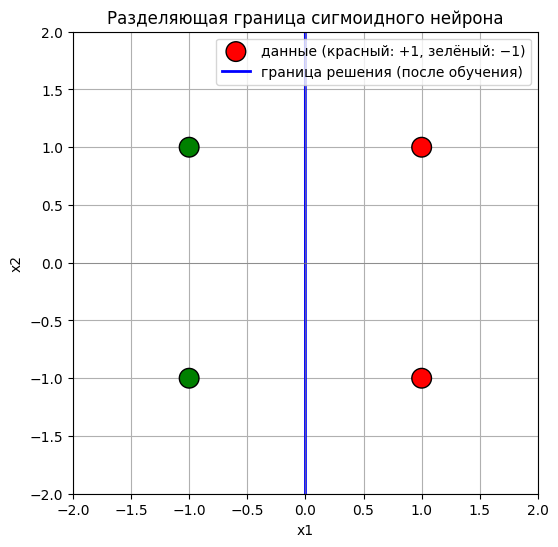

In [ ]:
plt.figure(figsize=(6, 6))
plt.scatter(x1, x2, c=['red', 'red', 'green', 'green'],
            s=200, edgecolors='k', zorder=3,
            label='данные (красный: +1, зелёный: −1)')

x1_line = np.linspace(-2, 2, 100)
x2_line = -(w_s[0] * x1_line + b_s) / w_s[1]
plt.plot(x1_line, x2_line, 'b-', linewidth=2,
         label='граница решения (после обучения)')

plt.xlim(-2, 2); plt.ylim(-2, 2)
plt.axhline(0, color='gray', linewidth=0.5)
plt.axvline(0, color='gray', linewidth=0.5)
plt.xlabel('x1'); plt.ylabel('x2')
plt.title('Разделяющая граница сигмоидного нейрона')
plt.legend()
plt.grid(True)
plt.show()

На графике видно, как изменяется выход нейрона при обучении (постепенно сдвигаем к целевому значению)

### **Задание 4**

4.1. визуализировать результат обучения для набора данных :

**# входное пространство**

x1 = np.array([1,1,-1,-1])
x2 = np.array([1,-1,-1,1])

x = np.vstack([x1,x2]).T

**# целевые значения для входов**

D=np.array([1,-1,1,-1])

**Линейная разделимость**

Введем понятие разделимость :
- линейная - можно поделить линейной границей
- линейно не разделимая - нельзя провести линейную границу

<img src='https://drive.google.com/uc?export=view&id=1jysvUhdc4EvJHhTbliZGFq8fRl9-L1Ek'>


Приведем пример линейно не разделимой модели примеров

In [ ]:
x1 = np.array([1,1,-1,-1])
x2 = np.array([1,-1,-1,1])

x = np.vstack([x1,x2]).T
x

array([[ 1,  1],
       [ 1, -1],
       [-1, -1],
       [-1,  1]])

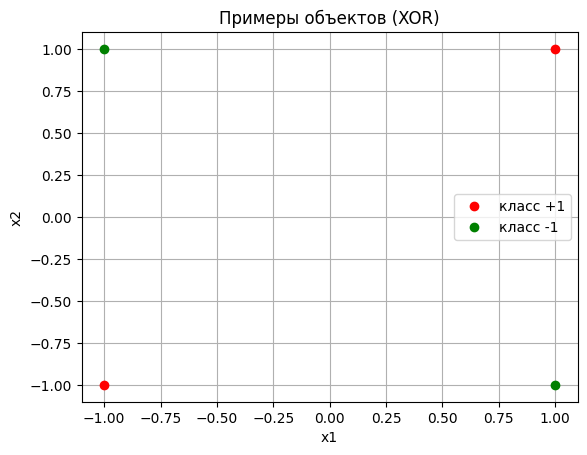

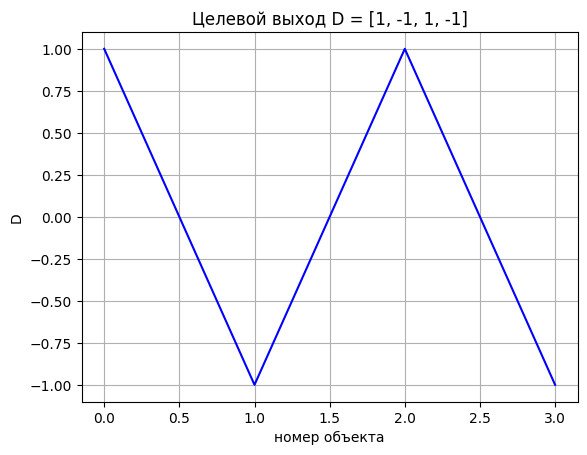

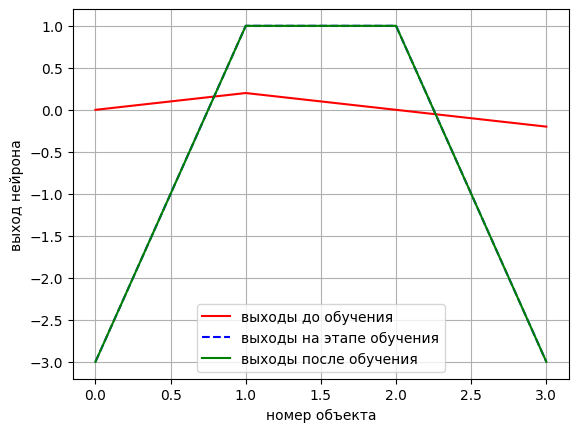

Предсказано: [-1.  1.  1. -1.]
Целевое:     [ 1 -1  1 -1]
Ошибок: 2 из 4
Accuracy: 0.50


In [ ]:
x1 = np.array([1, 1, -1, -1])
x2 = np.array([1, -1, -1, 1])

x = np.vstack([x1, x2]).T
D = np.array([1, -1, 1, -1])

plt.plot(x1[[0, 2]], x2[[0, 2]], 'or', label='класс +1')
plt.plot(x1[[1, 3]], x2[[1, 3]], 'og', label='класс -1')
plt.legend()
plt.xlabel('x1')
plt.ylabel('x2')
plt.title('Примеры объектов (XOR)')
plt.grid()
plt.show()

plt.plot(D, 'b')
plt.title('Целевой выход D = [1, -1, 1, -1]')
plt.xlabel('номер объекта')
plt.ylabel('D')
plt.grid()
plt.show()

w = np.array([0.1, -0.1])
b = 0.0

yt = linear_neuron(x=x, w=w, bias=b)
plt.plot(yt, 'r', label='выходы до обучения')

w_lin, b_lin, history_lin = delta_rule_linear(
    x, D, w, b, lr=0.5, epochs=50
)
history_lin = np.array(history_lin)

plt.plot(history_lin[-1], '--b', label='выходы на этапе обучения')
plt.plot(history_lin[-1], 'g', label='выходы после обучения')
plt.legend()
plt.xlabel('номер объекта')
plt.ylabel('выход нейрона')
plt.grid()
plt.show()

y_pred = np.sign(x @ w_lin + b_lin)
print("Предсказано:", y_pred)
print("Целевое:    ", D)
print(f"Ошибок: {np.sum(y_pred != D)} из {len(D)}")
print(f"Accuracy: {np.mean(y_pred == D):.2f}")

Нейрон не обучается (2 ошибки на 4 примера)

### **Задание 5**

5.1. Сделать комбинацию выходов нейронов (сигмоидных) с весами

5.2. визуализировать результат работы в двухмерном пространстве входов.

Можно строить сколько угодно сложные модели если :
- нейрон может это реализовать
- нейрон можно этому обучить

**Проверим, что можно построить из комбинаций нейронов:**

Скомбинируем нейроны y_out_21 и y_out_22

In [ ]:
x1 = np.array([1, 1, -1, -1])
x2 = np.array([1, -1, -1, 1])
x = np.vstack([x1, x2]).T
D = np.array([1, -1, 1, -1])
new_D1 = (D + 1) // 2

bias = -0.5
w_a = np.array([ 1.0,  1.0]);
w_b = np.array([-1.0, -1.0]);
w2 = np.array([20.0, 20.0]); b2 = -16.5

y_out21 = sigmoid_neuron(x=x, w=w_a, bias=bias)
y_out22 = sigmoid_neuron(x=x, w=w_b, bias=bias)

print("Выходы слоя 1:")
print(np.round(np.vstack([y_out21, y_out22]).T, 3))

x_new = np.vstack([y_out21, y_out22]).T



final_p = sigmoid_neuron(x=x_new, w=w2, bias=b2)

print("Финальные вероятности P(класс=1):", np.round(final_p, 3))
print("Предсказанные классы:            ", (final_p > 0.5).astype(int))
print("Истинные классы (new_D1):         ", new_D1)

Выходы слоя 1:
[[0.818 0.076]
 [0.378 0.378]
 [0.076 0.818]
 [0.378 0.378]]
Финальные вероятности P(класс=1): [0.797 0.198 0.797 0.198]
Предсказанные классы:             [1 0 1 0]
Истинные классы (new_D1):          [1 0 1 0]


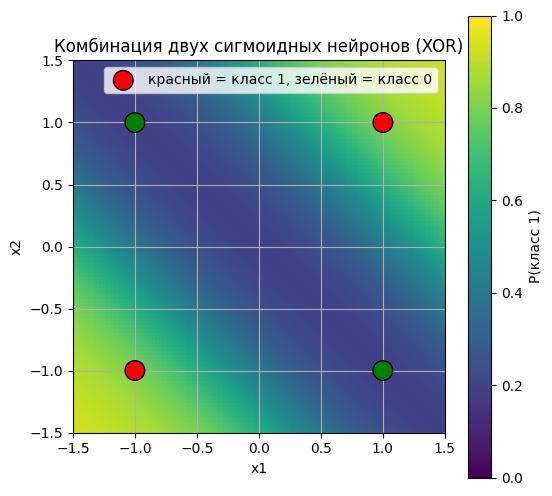

In [ ]:
N = 100
xx1 = np.linspace(-1.5, 1.5, N)
xx2 = np.linspace(-1.5, 1.5, N)
XX1, XX2 = np.meshgrid(xx1, xx2)
X_grid = np.hstack([XX1.flatten().reshape(-1, 1),
                    XX2.flatten().reshape(-1, 1)])   # (N², 2)

h1_grid = sigmoid_neuron(x=X_grid, w=w_a, bias=bias)
h2_grid = sigmoid_neuron(x=X_grid, w=w_b, bias=bias)
h_grid  = np.vstack([h1_grid, h2_grid]).T           # (N², 2)

final_grid = sigmoid_neuron(x=h_grid, w=w2, bias=b2)
Z = final_grid.reshape(N, N)

plt.figure(figsize=(6, 6))
im = plt.imshow(Z, origin='lower', extent=[-1.5, 1.5, -1.5, 1.5],
                vmin=0, vmax=1, cmap='viridis')
plt.colorbar(im, label='P(класс 1)')
plt.scatter(x1, x2, c=['red' if d == 1 else 'green' for d in new_D1],
            s=200, edgecolors='k', zorder=3,
            label='красный = класс 1, зелёный = класс 0')
plt.legend()
plt.xlabel('x1'); plt.ylabel('x2')
plt.title('Комбинация двух сигмоидных нейронов (XOR)')
plt.grid(True)
plt.show()

## комплекс нейронов

Объединим ответы 2-х нейронов в третьем (выходы 2-х первых - входы третьего)

In [ ]:
x_y2=np.hstack([y_out_21.reshape((100,1)),y_out_22.reshape((100,1))])
x_y2.shape

(100, 2)

Запустим нейрон и оказывается , что он может объединить решения неронов , т.е. 1 выставляем только там, где оба входных нейрона выставили 1. Остальные области помечены 0.

Покажем это на схеме

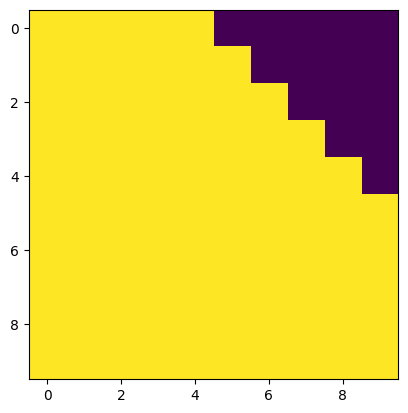

In [ ]:
yy2 = McCuloh_Pitts_neuron(x = x_y2, w = np.array([1,1]), bias = -0.5)
yy2=yy2.reshape((10,10))

plt.imshow((yy2 ))
plt.show()

Построим еще одно объединение  - "Уголком"

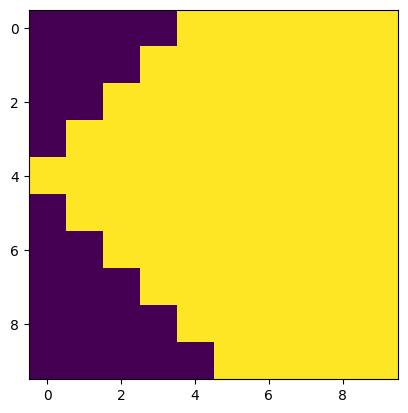

In [ ]:
x1 = np.array([np.linspace(-10,11,10).reshape((10,1))]*10).reshape((10,10))
x2 = x1.T
x2=x2.reshape((100,1))
x1=x1.reshape((100,1))

x = np.hstack([x1,x2])

w = np.array([0.9, -0.9])

y_out_31 = McCuloh_Pitts_neuron(x = x, w = w, bias = 10)
w = np.array([0.9, 0.9])

y_out_32 = McCuloh_Pitts_neuron(x = x, w = w, bias = 10)

x_y3=np.hstack([y_out_31.reshape((100,1)),y_out_32.reshape((100,1))])
x_y3.shape

yy3 = McCuloh_Pitts_neuron(x = x_y3, w = np.array([1,1]), bias = -0.5)
yy3=yy3.reshape((10,10))

plt.imshow((yy3 ))
plt.show()

Схема нейронной модели из 3-х нейронов ;

<img src='3_neurons.png'>


Это уже нейронная сеть!!!!

### Нейронная сеть

Слой - группа нейронов :
    - близкие функции
    - связаны с общим подмножеством нейронов
    
Слой на выходе - выходной

Слой на входе - рецептивный

**Формальная модель сети**


<img src='neuronet.png'>


Возможности сети:

- 2-х слойная сеть {0,1}n - произвольная булева функция (ДНФ)
- 2-х слойная сеть Rn - произвольный выпуклый многогранник
- 3-х слойная сеть Rn - произвольная не обязательно выпуклая область , не обязательно связная
- линейные операции + одна нелинейная - приблизит любу. непрерывную функцию с любой точностью

Пример 2-х слойная сеть Rn - произвольный выпуклый многогранник

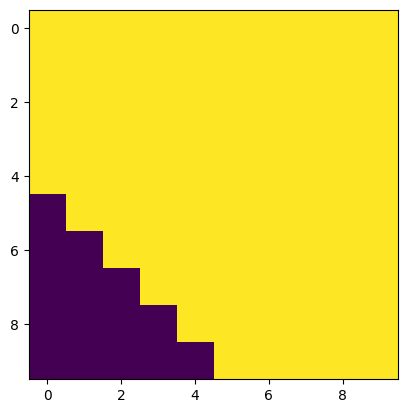

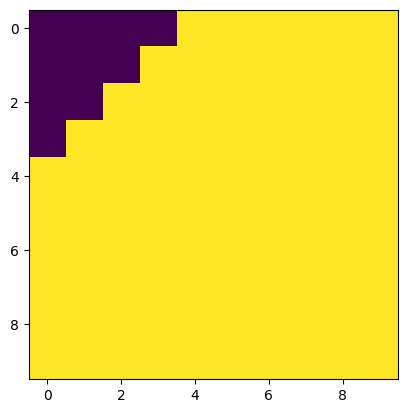

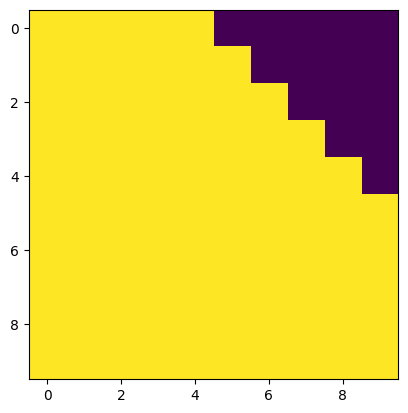

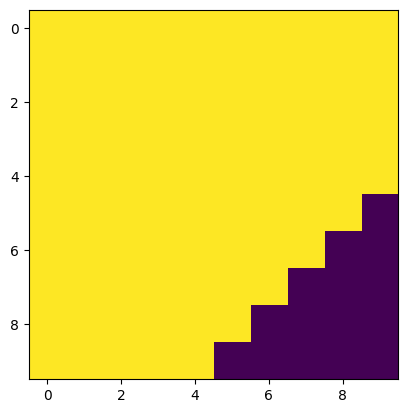

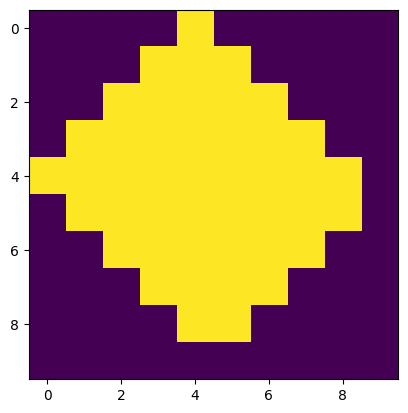

In [ ]:
x1 = np.array([np.linspace(-10,11,10).reshape((10,1))]*10).reshape((10,10))
x2 = x1.T
x2=x2.reshape((100,1))
x1=x1.reshape((100,1))

x = np.hstack([x1,x2])

w = np.array([0.9, -0.9])

y_out_31 = McCuloh_Pitts_neuron(x = x, w = w, bias = 10)
plt.imshow((y_out_31.reshape((10,10)) ))
plt.show()
w = np.array([0.9, 0.9])

y_out_32 = McCuloh_Pitts_neuron(x = x, w = w, bias = 10)
plt.imshow((y_out_32.reshape((10,10)) ))
plt.show()
w = np.array([-0.9, 0.9])

y_out_33 = McCuloh_Pitts_neuron(x = x, w = w, bias = 10)
plt.imshow((y_out_33.reshape((10,10)) ))
plt.show()
w = np.array([-0.9, -0.9])

y_out_34 = McCuloh_Pitts_neuron(x = x, w = w, bias = 10)
plt.imshow((y_out_34.reshape((10,10)) ))
plt.show()


x_y3=np.hstack([y_out_31.reshape((100,1)),y_out_32.reshape((100,1)), y_out_33.reshape((100,1)), y_out_34.reshape((100,1))])
x_y3.shape

yy3 = McCuloh_Pitts_neuron(x = x_y3, w = np.array([0.25,0.25,0.25,0.25]), bias = -0.5)
#yy3 = linear_neuron(x = x_y3, w = np.array([0.24,0.24,0.24,0.24]), bias = 0)
yy3=yy3.reshape((10,10))

plt.imshow((yy3 ))
plt.show()

In [ ]:
yy3

array([[0., 0., 0., 0., 1., 0., 0., 0., 0., 0.],
       [0., 0., 0., 1., 1., 1., 0., 0., 0., 0.],
       [0., 0., 1., 1., 1., 1., 1., 0., 0., 0.],
       [0., 1., 1., 1., 1., 1., 1., 1., 0., 0.],
       [1., 1., 1., 1., 1., 1., 1., 1., 1., 0.],
       [0., 1., 1., 1., 1., 1., 1., 1., 1., 0.],
       [0., 0., 1., 1., 1., 1., 1., 1., 0., 0.],
       [0., 0., 0., 1., 1., 1., 1., 0., 0., 0.],
       [0., 0., 0., 0., 1., 1., 0., 0., 0., 0.],
       [0., 0., 0., 0., 0., 0., 0., 0., 0., 0.]])

<img src='https://drive.google.com/uc?export=view&id=1WHFe1TqyDG2bVJKOoNL2YWOFMPbuuTxt'>


### Что показано в Задании 5

одиночный нейрон решает только линейно разделимые задачи.
Комбинация нейронов позволяет строить выпуклые многоугольники (2 слоя),
произвольные (в т.ч. невыпуклые) области (3 слоя) и приближать любую
непрерывную функцию (теорема о полноте).

3-х слойная сеть Rn - произвольная не обязательно выпуклая область

In [ ]:
# Image(filename='8.png', width=600)

<img src='8.png'>

<img src='https://drive.google.com/uc?export=view&id=1FWpEBzvk2WQW99tAuASlaHO3tu09wnaf'>


## Резюме

1. Нейрон - биологическое подобие
2. Нейрон - обучаем
3. Нейрон - простая функция
4. Нейронная сеть - сложная функция
5. Нейронная сеть - обучаема